<a href="https://colab.research.google.com/github/AnshM401/Exp-6/blob/main/dmbi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:

import os

os.listdir('/content/drive/MyDrive')


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive'

In [ ]:

import pandas as pd

file_path = '/content/drive/MyDrive/graphics_card_sales_synthetic_dataset.xlsx'

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print(df.head())
print("\nDataset shape:", df.shape)


Dataset loaded successfully!
   Sale_ID Graphic_Card_ID      Model_Name                GPU_Model Brand_ID  \
0  SL00001            G009     RX 7900 XTX    Radeon RX 7000 Series      B02   
1  SL00002            G012       RTX A4000  NVIDIA RTX Professional      B01   
2  SL00003            G011        Arc A770       Intel Arc A Series      B03   
3  SL00004            G004  RTX 4080 Super    GeForce RTX 40 Series      B01   
4  SL00005            G003  RTX 4070 Super    GeForce RTX 40 Series      B01   

  Brand_Name            Manufacturer Category_ID Category_Name  \
0        AMD  Advanced Micro Devices         C04   Workstation   
1     NVIDIA      NVIDIA Corporation         C04   Workstation   
2      Intel       Intel Corporation         C02     Mid-Range   
3     NVIDIA      NVIDIA Corporation         C03      High-End   
4     NVIDIA      NVIDIA Corporation         C03      High-End   

                        Usage_Type  ...  Year Store_ID  \
0    Professional rendering and AI 

In [ ]:

# Step 2: Inspect the dataset

print("1. Dataset dimensions:")
print(df.shape)

print("\n2. Missing values in each column:")
print(df.isnull().sum())

print("\n3. Number of duplicate rows:")
print(df.duplicated().sum())

print("\n4. Data types of each column:")
print(df.dtypes)


1. Dataset dimensions:
(1220, 38)

2. Missing values in each column:
Sale_ID             0
Graphic_Card_ID     0
Model_Name          0
GPU_Model           0
Brand_ID            0
Brand_Name          0
Manufacturer        0
Category_ID         0
Category_Name       0
Usage_Type          0
VRAM_GB             0
Memory_Type        16
Customer_ID         0
Customer_Name       0
Email              19
City_ID             0
City_Name           0
State_ID            0
State_Name          0
Country_ID          0
Country_Name        0
Date_ID             0
Full_Date           0
Month_ID            0
Month_Name          0
Quarter_ID          0
Quarter_Name        0
Year_ID             0
Year                0
Store_ID            0
Store_Name          0
Store_Type_ID       0
Store_Type          0
Quantity            0
Unit_Price          0
Discount           17
Total_Amount        0
Sales_Category      0
dtype: int64

3. Number of duplicate rows:
20

4. Data types of each column:
Sale_ID           

In [ ]:

# Step 3: Data cleaning

# Create a copy so the original dataset remains unchanged
df_clean = df.copy()

# Count duplicate rows before removing them
duplicates_before = df_clean.duplicated().sum()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Count missing Discount values
missing_discount = df_clean["Discount"].isnull().sum()

# Fill missing Discount values with the median
median_discount = df_clean["Discount"].median()

df_clean["Discount"] = df_clean["Discount"].fillna(median_discount)

# Display results
print("Duplicate rows removed:", duplicates_before)
print("Rows remaining:", len(df_clean))
print("Missing Discount values filled:", missing_discount)

print("\nTotal missing values after cleaning:")
print(df_clean.isnull().sum().sum())

print("\nCleaned dataset:")
print(df_clean.head())


Duplicate rows removed: 20
Rows remaining: 1200
Missing Discount values filled: 16

Total missing values after cleaning:
33

Cleaned dataset:
   Sale_ID Graphic_Card_ID      Model_Name                GPU_Model Brand_ID  \
0  SL00001            G009     RX 7900 XTX    Radeon RX 7000 Series      B02   
1  SL00002            G012       RTX A4000  NVIDIA RTX Professional      B01   
2  SL00003            G011        Arc A770       Intel Arc A Series      B03   
3  SL00004            G004  RTX 4080 Super    GeForce RTX 40 Series      B01   
4  SL00005            G003  RTX 4070 Super    GeForce RTX 40 Series      B01   

  Brand_Name            Manufacturer Category_ID Category_Name  \
0        AMD  Advanced Micro Devices         C04   Workstation   
1     NVIDIA      NVIDIA Corporation         C04   Workstation   
2      Intel       Intel Corporation         C02     Mid-Range   
3     NVIDIA      NVIDIA Corporation         C03      High-End   
4     NVIDIA      NVIDIA Corporation         C0

In [ ]:




# Show only columns that still contain missing values

missing = df_clean.isnull().sum()

print("Columns with missing values:")
print(missing[missing > 0])

print("\nTotal missing values:", df_clean.isnull().sum().sum())


Columns with missing values:
Memory_Type    15
Email          18
dtype: int64

Total missing values: 33


In [ ]:

# Fill missing Memory_Type values with the most frequent type
memory_mode = df_clean["Memory_Type"].mode()

if not memory_mode.empty:
    df_clean["Memory_Type"] = df_clean["Memory_Type"].fillna(
        memory_mode.iloc[0]
    )
else:
    df_clean["Memory_Type"] = df_clean["Memory_Type"].fillna("Unknown")

# Fill missing emails with "Unknown"
df_clean["Email"] = df_clean["Email"].fillna("Unknown")

# Verify the results
print("Missing values after handling:")
print(df_clean.isnull().sum().sum())

print("\nRemaining columns with missing values:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])


Missing values after handling:
0

Remaining columns with missing values:
Series([], dtype: int64)


In [ ]:

# Step 6: Encode categorical columns

import pandas as pd
import numpy as np

# Keep the cleaned dataset unchanged for Experiment 3
df_preprocessed = df_clean.copy()

# Identify ID columns so they are not encoded as features
id_cols = [
    col for col in df_preprocessed.columns
    if col.strip().lower().endswith("_id")
]

# Do not encode customer names and email addresses
personal_cols = [
    col for col in df_preprocessed.columns
    if col.strip().lower() in ["customer_name", "email"]
]

# Identify categorical columns
categorical_cols = [
    col for col in df_preprocessed.select_dtypes(
        include=["object", "string", "category"]
    ).columns
    if col not in id_cols and col not in personal_cols
]

print("Categorical columns to encode:")
print(categorical_cols)

# Convert categories into numerical columns
df_preprocessed = pd.get_dummies(
    df_preprocessed,
    columns=categorical_cols,
    dtype=int
)

print("\nDataset after categorical encoding:")
print(df_preprocessed.head())
print("\nNew dataset dimensions:", df_preprocessed.shape)


Categorical columns to encode:
['Model_Name', 'GPU_Model', 'Brand_Name', 'Manufacturer', 'Category_Name', 'Usage_Type', 'Memory_Type', 'City_Name', 'State_Name', 'Country_Name', 'Full_Date', 'Month_Name', 'Quarter_Name', 'Store_Name', 'Store_Type', 'Sales_Category']

Dataset after categorical encoding:
   Sale_ID Graphic_Card_ID Brand_ID Category_ID  VRAM_GB Customer_ID  \
0  SL00001            G009      B02         C04       24       CU174   
1  SL00002            G012      B01         C04       16       CU199   
2  SL00003            G011      B03         C02       16       CU019   
3  SL00004            G004      B01         C03       16       CU126   
4  SL00005            G003      B01         C03       12       CU046   

  Customer_Name                        Email City_ID State_ID  ...  \
0   Kabir Reddy                      Unknown    CI08     ST07  ...   
1      Neha Das     neha.das199@example.test    CI07     ST06  ...   
2   Meera Gupta   meera.gupta19@example.test    CI07 

In [ ]:

# Step 7: Standardize numerical columns

from sklearn.preprocessing import StandardScaler

# Select original numerical columns, excluding IDs
numeric_cols = [
    col for col in df_clean.select_dtypes(include=np.number).columns
    if col not in id_cols
]

scaler = StandardScaler()

df_preprocessed[numeric_cols] = scaler.fit_transform(
    df_preprocessed[numeric_cols]
)

print("Numerical columns standardized:")
print(numeric_cols)

print("\nPreprocessed dataset:")
print(df_preprocessed.head())

print("\nMissing values remaining:",
      df_preprocessed.isnull().sum().sum())


Numerical columns standardized:
['VRAM_GB', 'Year', 'Quantity', 'Unit_Price', 'Discount', 'Total_Amount']

Preprocessed dataset:
   Sale_ID Graphic_Card_ID Brand_ID Category_ID   VRAM_GB Customer_ID  \
0  SL00001            G009      B02         C04  1.740262       CU174   
1  SL00002            G012      B01         C04  0.214831       CU199   
2  SL00003            G011      B03         C02  0.214831       CU019   
3  SL00004            G004      B01         C03  0.214831       CU126   
4  SL00005            G003      B01         C03 -0.547884       CU046   

  Customer_Name                        Email City_ID State_ID  ...  \
0   Kabir Reddy                      Unknown    CI08     ST07  ...   
1      Neha Das     neha.das199@example.test    CI07     ST06  ...   
2   Meera Gupta   meera.gupta19@example.test    CI07     ST06  ...   
3   Priya Patel  priya.patel126@example.test    CI07     ST06  ...   
4  Aarav Sharma  aarav.sharma46@example.test    CI05     ST04  ...   

  Store_Nam

In [ ]:

output_path = (
    "/content/drive/MyDrive/"
    "graphics_card_sales_preprocessed.xlsx"
)

df_preprocessed.to_excel(output_path, index=False)

print("Preprocessed file saved to:")
print(output_path)


Preprocessed file saved to:
/content/drive/MyDrive/graphics_card_sales_preprocessed.xlsx


In [ ]:

# EXPERIMENT 3: EXPLORATORY DATA ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Display the first five records
print("First five records:")
display(df_clean.head())

# 2. Display dataset dimensions
print("\nDataset dimensions (rows, columns):")
print(df_clean.shape)

# 3. Display column names and data types
print("\nDataset information:")
df_clean.info()

# 4. Summary statistics for numerical columns
print("\nNumerical summary:")
display(
    df_clean[
        ["VRAM_GB", "Quantity", "Unit_Price",
         "Discount", "Total_Amount"]
    ].describe()
)



First five records:


,Sale_ID,Graphic_Card_ID,Model_Name,GPU_Model,Brand_ID,Brand_Name,Manufacturer,Category_ID,Category_Name,Usage_Type,...,Year,Store_ID,Store_Name,Store_Type_ID,Store_Type,Quantity,Unit_Price,Discount,Total_Amount,Sales_Category
0,SL00001,G009,RX 7900 XTX,Radeon RX 7000 Series,B02,AMD,Advanced Micro Devices,C04,Workstation,Professional rendering and AI,...,2025,S001,TechHub Mumbai,T01,Flagship,2,1009.05,0.05,2018.10,High
1,SL00002,G012,RTX A4000,NVIDIA RTX Professional,B01,NVIDIA,NVIDIA Corporation,C04,Workstation,Professional rendering and AI,...,2024,S006,Silicon Bazaar Hyderabad,T03,Online Fulfilment,1,1130.68,0.05,1074.15,High
2,SL00003,G011,Arc A770,Intel Arc A Series,B03,Intel,Intel Corporation,C02,Mid-Range,Mainstream gaming,...,2024,S007,FrameRate Kolkata,T02,Retail,2,346.80,0.10,624.24,Medium
3,SL00004,G004,RTX 4080 Super,GeForce RTX 40 Series,B01,NVIDIA,NVIDIA Corporation,C03,High-End,Competitive gaming and creation,...,2024,S006,Silicon Bazaar Hyderabad,T03,Online Fulfilment,1,1032.81,0.00,1032.81,Medium
4,SL00005,G003,RTX 4070 Super,GeForce RTX 40 Series,B01,NVIDIA,NVIDIA Corporation,C03,High-End,Competitive gaming and creation,...,2025,S001,TechHub Mumbai,T01,Flagship,2,611.45,0.00,1222.90,High



Dataset dimensions (rows, columns):
(1200, 38)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 1200 entries, 0 to 1199
Data columns (total 38 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Sale_ID          1200 non-null   object 
 1   Graphic_Card_ID  1200 non-null   object 
 2   Model_Name       1200 non-null   object 
 3   GPU_Model        1200 non-null   object 
 4   Brand_ID         1200 non-null   object 
 5   Brand_Name       1200 non-null   object 
 6   Manufacturer     1200 non-null   object 
 7   Category_ID      1200 non-null   object 
 8   Category_Name    1200 non-null   object 
 9   Usage_Type       1200 non-null   object 
 10  VRAM_GB          1200 non-null   int64  
 11  Memory_Type      1200 non-null   object 
 12  Customer_ID      1200 non-null   object 
 13  Customer_Name    1200 non-null   object 
 14  Email            1200 non-null   object 
 15  City_ID          1200 non-null   object 


,VRAM_GB,Quantity,Unit_Price,Discount,Total_Amount
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,14.873333,1.193333,662.308058,0.049458,756.062642
std,5.246608,0.413640,415.512761,0.053346,587.973584
min,8.000000,1.000000,227.010000,0.000000,192.960000
25%,12.000000,1.000000,322.857500,0.000000,351.385000
50%,16.000000,1.000000,484.415000,0.050000,525.005000
75%,16.000000,1.000000,983.122500,0.100000,975.482500
max,24.000000,3.000000,1757.350000,0.150000,5212.410000


In [ ]:

# EXPERIMENT 3 - STEP 2
# Measures of Central Tendency

numeric_cols = [
    "VRAM_GB",
    "Quantity",
    "Unit_Price",
    "Discount",
    "Total_Amount"
]

print("CENTRAL TENDENCY OF NUMERICAL ATTRIBUTES\n")

for col in numeric_cols:
    print("Attribute:", col)
    print("Mean:", df_clean[col].mean())
    print("Median:", df_clean[col].median())
    print("Mode:", df_clean[col].mode().tolist())
    print("-" * 40)

# Mode of categorical attributes
categorical_cols = [
    "Brand_Name",
    "Category_Name",
    "Usage_Type",
    "Memory_Type",
    "Sales_Category"
]

print("\nMODE OF CATEGORICAL ATTRIBUTES\n")

for col in categorical_cols:
    print(col, ":", df_clean[col].mode().tolist())


CENTRAL TENDENCY OF NUMERICAL ATTRIBUTES

Attribute: VRAM_GB
Mean: 14.873333333333333
Median: 16.0
Mode: [16]
----------------------------------------
Attribute: Quantity
Mean: 1.1933333333333334
Median: 1.0
Mode: [1]
----------------------------------------
Attribute: Unit_Price
Mean: 662.3080583333334
Median: 484.41499999999996
Mode: [253.39, 255.29, 271.74, 272.6, 284.8, 297.35, 327.17, 449.58, 1024.74, 1682.08]
----------------------------------------
Attribute: Discount
Mean: 0.049458333333333326
Median: 0.05
Mode: [0.0]
----------------------------------------
Attribute: Total_Amount
Mean: 756.0626416666667
Median: 525.005
Mode: [294.45]
----------------------------------------

MODE OF CATEGORICAL ATTRIBUTES

Brand_Name : ['NVIDIA']
Category_Name : ['Mid-Range']
Usage_Type : ['Mainstream gaming']
Memory_Type : ['GDDR6']
Sales_Category : ['Medium']


In [ ]:

# EXPERIMENT 3 - STEP 3
# Measures of Dispersion

numeric_cols = [
    "VRAM_GB",
    "Quantity",
    "Unit_Price",
    "Discount",
    "Total_Amount"
]

print("MEASURES OF DISPERSION\n")

for col in numeric_cols:
    data = df_clean[col]

    standard_deviation = data.std()
    variance = data.var()
    data_range = data.max() - data.min()
    iqr = data.quantile(0.75) - data.quantile(0.25)

    print("Attribute:", col)
    print("Standard Deviation:", round(standard_deviation, 3))
    print("Variance:", round(variance, 3))
    print("Range:", round(data_range, 3))
    print("Interquartile Range (IQR):", round(iqr, 3))
    print("-" * 40)


MEASURES OF DISPERSION

Attribute: VRAM_GB
Standard Deviation: 5.247
Variance: 27.527
Range: 16
Interquartile Range (IQR): 4.0
----------------------------------------
Attribute: Quantity
Standard Deviation: 0.414
Variance: 0.171
Range: 2
Interquartile Range (IQR): 0.0
----------------------------------------
Attribute: Unit_Price
Standard Deviation: 415.513
Variance: 172650.855
Range: 1530.34
Interquartile Range (IQR): 660.265
----------------------------------------
Attribute: Discount
Standard Deviation: 0.053
Variance: 0.003
Range: 0.15
Interquartile Range (IQR): 0.1
----------------------------------------
Attribute: Total_Amount
Standard Deviation: 587.974
Variance: 345712.936
Range: 5019.45
Interquartile Range (IQR): 624.098
----------------------------------------


Correlation Matrix:


,VRAM_GB,Quantity,Unit_Price,Discount,Total_Amount
VRAM_GB,1.00,0.03,0.79,-0.03,0.66
Quantity,0.03,1.00,0.02,-0.01,0.48
Unit_Price,0.79,0.02,1.00,-0.02,0.83
Discount,-0.03,-0.01,-0.02,1.00,-0.10
Total_Amount,0.66,0.48,0.83,-0.10,1.00


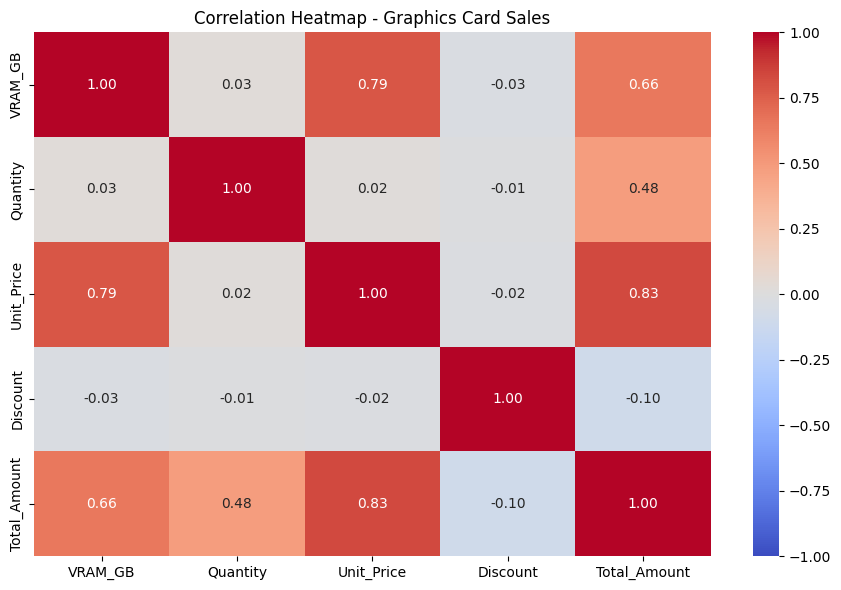

In [ ]:

# EXPERIMENT 3 - STEP 4
# Correlation Analysis

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = [
    "VRAM_GB",
    "Quantity",
    "Unit_Price",
    "Discount",
    "Total_Amount"
]

# Calculate Pearson correlation coefficients
correlation_matrix = df_clean[numeric_cols].corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

# Plot the correlation heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap - Graphics Card Sales")
plt.tight_layout()
plt.show()


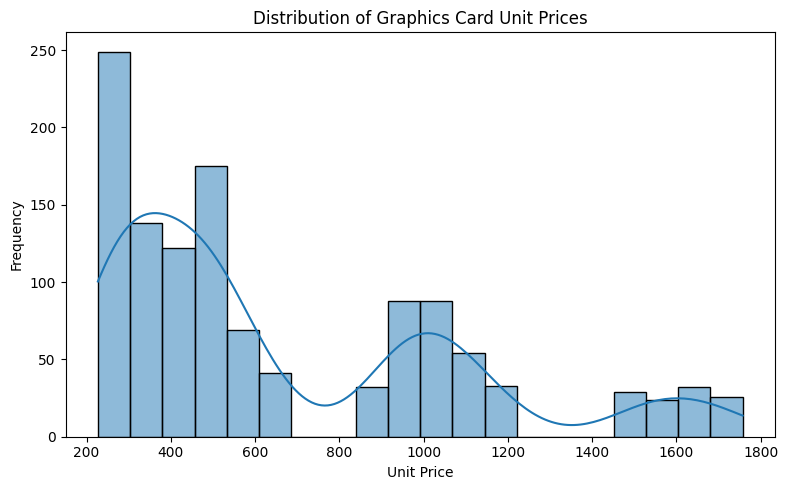

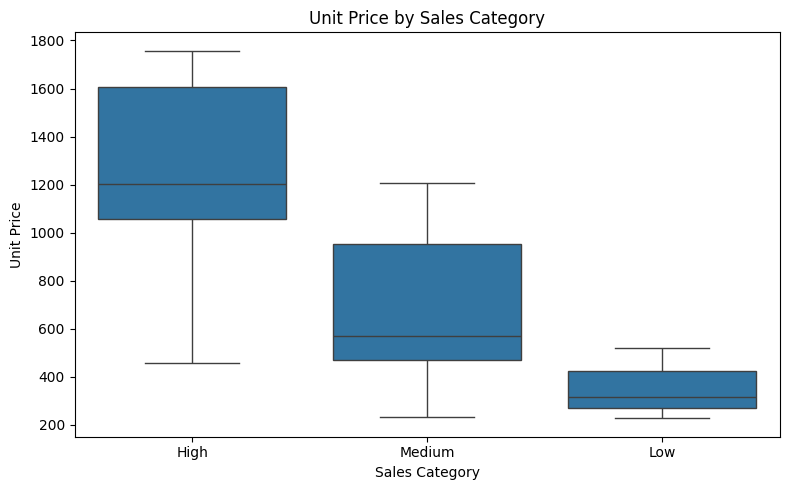

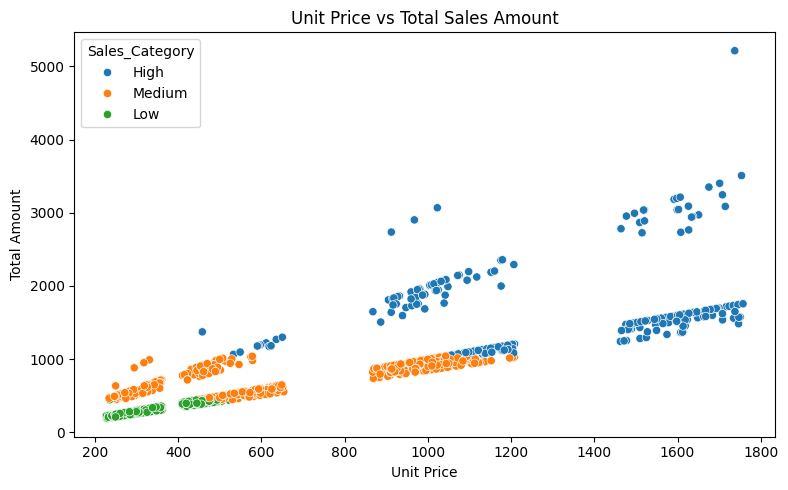

In [ ]:

# EXPERIMENT 3 - STEP 5
# Data Visualization

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Histogram: Distribution of unit prices
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="Unit_Price", bins=20, kde=True)
plt.title("Distribution of Graphics Card Unit Prices")
plt.xlabel("Unit Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# 2. Boxplot: Unit prices by sales category
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="Sales_Category", y="Unit_Price")
plt.title("Unit Price by Sales Category")
plt.xlabel("Sales Category")
plt.ylabel("Unit Price")
plt.tight_layout()
plt.show()


# 3. Scatter plot: Unit price versus total amount
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_clean,
    x="Unit_Price",
    y="Total_Amount",
    hue="Sales_Category"
)
plt.title("Unit Price vs Total Sales Amount")
plt.xlabel("Unit Price")
plt.ylabel("Total Amount")
plt.tight_layout()
plt.show()


In [ ]:

# Check the classification target

print("Sales Category values:")
print(df_clean["Sales_Category"].unique())

print("\nNumber of records in each category:")
print(df_clean["Sales_Category"].value_counts())

print("\nMissing values:")
print(df_clean["Sales_Category"].isnull().sum())


Sales Category values:
['High' 'Medium' 'Low']

Number of records in each category:
Sales_Category
Medium    512
Low       458
High      230
Name: count, dtype: int64

Missing values:
0


In [ ]:

# EXPERIMENT 4 - STEP 1
# Verify classification target

print("Sales Category values:")
print(df_clean["Sales_Category"].unique())

print("\nNumber of records in each category:")
print(df_clean["Sales_Category"].value_counts())

print("\nCheck relationship with sales attributes:")
display(
    df_clean.groupby("Sales_Category")[
        ["Total_Amount", "Unit_Price", "Quantity",
         "Discount", "VRAM_GB"]
    ].agg(["mean", "min", "max"]).round(2)
)


Sales Category values:
['High' 'Medium' 'Low']

Number of records in each category:
Sales_Category
Medium    512
Low       458
High      230
Name: count, dtype: int64

Check relationship with sales attributes:


Total_Amount                   Unit_Price                   \
                       mean      min      max       mean     min      max   
Sales_Category                                                              
High                1712.52  1050.07  5212.41    1303.54  457.94  1757.35   
Low                  319.76   192.96   449.98     338.74  227.01   520.86   
Medium               716.69   450.85  1047.30     663.70  233.81  1207.70   

               Quantity         Discount            VRAM_GB          
                   mean min max     mean  min   max    mean min max  
Sales_Category                                                       
High               1.43   1   3     0.04  0.0  0.15   20.28  12  24  
Low                1.00   1   2     0.06  0.0  0.15   11.36   8  16  
Medium             1.26   1   3     0.05  0.0  0.15   15.59   8  24

In [ ]:

# EXPERIMENT 4 - PREPARE CLASSIFICATION DATASET

# Select meaningful input attributes
features = [
    "Model_Name",
    "GPU_Model",
    "Brand_Name",
    "Manufacturer",
    "Category_Name",
    "Usage_Type",
    "VRAM_GB",
    "Memory_Type",
    "City_Name",
    "State_Name",
    "Country_Name",
    "Month_Name",
    "Quarter_Name",
    "Year",
    "Store_Name",
    "Store_Type"
]

# Add the target variable
target = "Sales_Category"

# Create classification dataset
classification_df = df_clean[features + [target]].copy()

# Ensure target is categorical
classification_df[target] = classification_df[target].astype(str)

# Check dataset
print("Classification Dataset:")
display(classification_df.head())

print("\nDataset Shape:")
print(classification_df.shape)

print("\nClass Distribution:")
print(classification_df[target].value_counts())

print("\nMissing Values:")
print(classification_df.isnull().sum().sum())

# Export as CSV
output_path = "/content/drive/MyDrive/graphics_card_classification.csv"

classification_df.to_csv(output_path, index=False, encoding="utf-8-sig")

print("\nClassification dataset exported successfully!")
print(output_path)


Classification Dataset:


,Model_Name,GPU_Model,Brand_Name,Manufacturer,Category_Name,Usage_Type,VRAM_GB,Memory_Type,City_Name,State_Name,Country_Name,Month_Name,Quarter_Name,Year,Store_Name,Store_Type,Sales_Category
0,RX 7900 XTX,Radeon RX 7000 Series,AMD,Advanced Micro Devices,Workstation,Professional rendering and AI,24,GDDR6,Ahmedabad,Gujarat,India,June,Q2,2025,TechHub Mumbai,Flagship,High
1,RTX A4000,NVIDIA RTX Professional,NVIDIA,NVIDIA Corporation,Workstation,Professional rendering and AI,16,GDDR6,Kolkata,West Bengal,India,January,Q1,2024,Silicon Bazaar Hyderabad,Online Fulfilment,High
2,Arc A770,Intel Arc A Series,Intel,Intel Corporation,Mid-Range,Mainstream gaming,16,GDDR6,Kolkata,West Bengal,India,January,Q1,2024,FrameRate Kolkata,Retail,Medium
3,RTX 4080 Super,GeForce RTX 40 Series,NVIDIA,NVIDIA Corporation,High-End,Competitive gaming and creation,16,GDDR6X,Kolkata,West Bengal,India,April,Q2,2024,Silicon Bazaar Hyderabad,Online Fulfilment,Medium
4,RTX 4070 Super,GeForce RTX 40 Series,NVIDIA,NVIDIA Corporation,High-End,Competitive gaming and creation,12,GDDR6X,Delhi,Delhi,India,June,Q2,2025,TechHub Mumbai,Flagship,High



Dataset Shape:
(1200, 17)

Class Distribution:
Sales_Category
Medium    512
Low       458
High      230
Name: count, dtype: int64

Missing Values:
0

Classification dataset exported successfully!
/content/drive/MyDrive/graphics_card_classification.csv


In [ ]:

# EXPERIMENT 8 - STEP 1
# Prepare dataset for K-Means Clustering

import pandas as pd
import numpy as np

# Select numerical attributes for clustering
features = [
    "VRAM_GB",
    "Quantity",
    "Unit_Price",
    "Discount"
]

# Create a separate clustering dataset
df_cluster = df_clean[features].copy()

print("Dataset Shape:")
print(df_cluster.shape)

print("\nFirst 5 Records:")
display(df_cluster.head())

print("\nMissing Values:")
print(df_cluster.isnull().sum())

print("\nStatistical Summary:")
display(df_cluster.describe())


Dataset Shape:
(1200, 4)

First 5 Records:


,VRAM_GB,Quantity,Unit_Price,Discount
0,24,2,1009.05,0.05
1,16,1,1130.68,0.05
2,16,2,346.80,0.10
3,16,1,1032.81,0.00
4,12,2,611.45,0.00



Missing Values:
VRAM_GB       0
Quantity      0
Unit_Price    0
Discount      0
dtype: int64

Statistical Summary:


,VRAM_GB,Quantity,Unit_Price,Discount
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,14.873333,1.193333,662.308058,0.049458
std,5.246608,0.413640,415.512761,0.053346
min,8.000000,1.000000,227.010000,0.000000
25%,12.000000,1.000000,322.857500,0.000000
50%,16.000000,1.000000,484.415000,0.050000
75%,16.000000,1.000000,983.122500,0.100000
max,24.000000,3.000000,1757.350000,0.150000


In [ ]:

# EXPERIMENT 8 - STEP 2
# Standardize numerical features

from sklearn.preprocessing import StandardScaler
import pandas as pd

# Create scaler
scaler = StandardScaler()

# Standardize the selected features
X_scaled = scaler.fit_transform(df_cluster)

# Convert scaled data back into a DataFrame
df_scaled = pd.DataFrame(
    X_scaled,
    columns=df_cluster.columns
)

print("Standardization completed successfully!")

print("\nFirst 5 standardized records:")
display(df_scaled.head())

print("\nMean of standardized features:")
print(df_scaled.mean().round(4))

print("\nStandard deviation:")
print(df_scaled.std(ddof=0).round(4))


Standardization completed successfully!

First 5 standardized records:


,VRAM_GB,Quantity,Unit_Price,Discount
0,1.740262,1.950979,0.834840,0.010158
1,0.214831,-0.467590,1.127684,0.010158
2,0.214831,1.950979,-0.759639,0.947821
3,0.214831,-0.467590,0.892046,-0.927505
4,-0.547884,1.950979,-0.122449,-0.927505



Mean of standardized features:
VRAM_GB       0.0
Quantity     -0.0
Unit_Price   -0.0
Discount      0.0
dtype: float64

Standard deviation:
VRAM_GB       1.0
Quantity      1.0
Unit_Price    1.0
Discount      1.0
dtype: float64


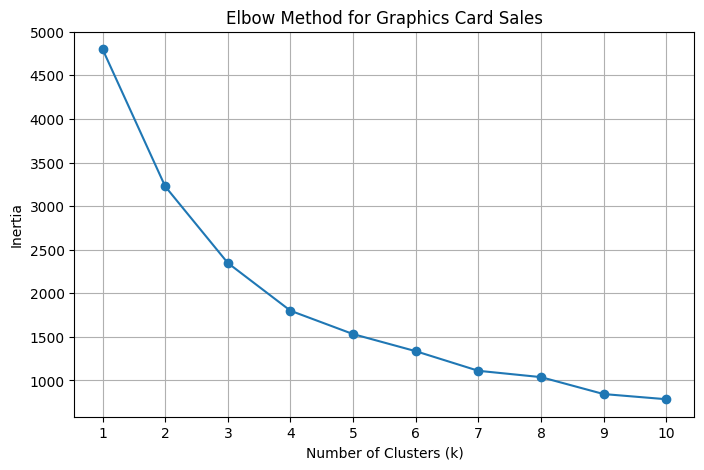

In [ ]:

# EXPERIMENT 8 - STEP 3
# Elbow Method for K-Means Clustering

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Store inertia values
inertia = []

# Test different numbers of clusters
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

# Plot the elbow graph
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_range),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Graphics Card Sales")
plt.xticks(list(k_range))
plt.grid(True)

plt.show()


In [ ]:

# EXPERIMENT 8 - STEP 4
# Apply K-Means Clustering

from sklearn.cluster import KMeans

# Choose number of clusters from Elbow Method
k = 4

# Create K-Means model
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

# Train model and assign clusters
cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to our dataset
df_cluster["Cluster"] = cluster_labels

print("K-Means Clustering completed successfully!")

print("\nFirst 10 records with clusters:")
display(df_cluster.head(10))

print("\nNumber of records in each cluster:")
print(df_cluster["Cluster"].value_counts().sort_index())

print("\nTotal records:")
print(len(df_cluster))

print("\nK-Means Inertia:")
print(round(kmeans.inertia_, 2))


K-Means Clustering completed successfully!

First 10 records with clusters:


,VRAM_GB,Quantity,Unit_Price,Discount,Cluster
0,24,2,1009.05,0.05,1
1,16,1,1130.68,0.05,3
2,16,2,346.80,0.10,1
3,16,1,1032.81,0.00,3
4,12,2,611.45,0.00,1
5,16,1,450.48,0.15,0
6,8,1,273.72,0.15,0
7,16,1,489.97,0.05,2
8,12,1,418.04,0.00,2
9,16,1,1041.01,0.00,3



Number of records in each cluster:
Cluster
0    207
1    198
2    478
3    317
Name: count, dtype: int64

Total records:
1200

K-Means Inertia:
1800.16


In [ ]:

# EXPERIMENT 8 - STEP 5
# Evaluate K-Means Clustering

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

# Calculate Silhouette Score
silhouette = silhouette_score(
    X_scaled,
    cluster_labels
)

# Calculate Davies-Bouldin Index
db_index = davies_bouldin_score(
    X_scaled,
    cluster_labels
)

# Get Inertia
inertia_value = kmeans.inertia_

# Display results
print("K-MEANS CLUSTERING PERFORMANCE")
print("--------------------------------")

print("Number of Clusters:", k)

print(f"Silhouette Score: {silhouette:.4f}")

print(f"Inertia: {inertia_value:.2f}")

print(f"Davies-Bouldin Index: {db_index:.4f}")

print("\nCluster Distribution:")
print(
    df_cluster["Cluster"]
    .value_counts()
    .sort_index()
)


K-MEANS CLUSTERING PERFORMANCE
--------------------------------
Number of Clusters: 4
Silhouette Score: 0.3904
Inertia: 1800.16
Davies-Bouldin Index: 0.9132

Cluster Distribution:
Cluster
0    207
1    198
2    478
3    317
Name: count, dtype: int64


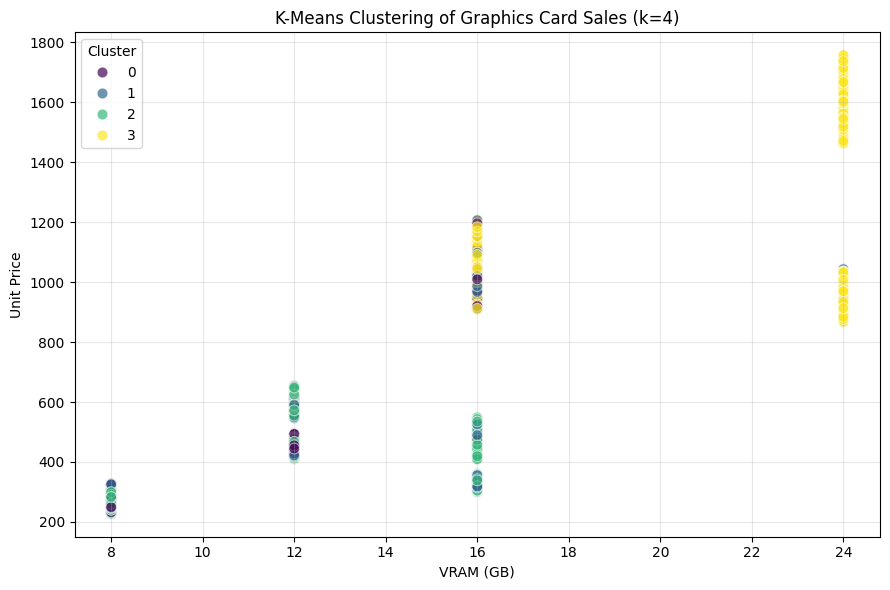

In [ ]:

# EXPERIMENT 8 - STEP 6
# Visualize K-Means Clustering Results

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))

# Create scatter plot
sns.scatterplot(
    data=df_cluster,
    x="VRAM_GB",
    y="Unit_Price",
    hue="Cluster",
    palette="viridis",
    s=60,
    alpha=0.7
)

plt.title("K-Means Clustering of Graphics Card Sales (k=4)")
plt.xlabel("VRAM (GB)")
plt.ylabel("Unit Price")
plt.legend(title="Cluster")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# EXPERIMENT 8 - STEP 7
# Analyze characteristics of each cluster

# Calculate mean values for each cluster
cluster_summary = df_cluster.groupby("Cluster")[
    ["VRAM_GB", "Quantity", "Unit_Price", "Discount"]
].mean().round(2)

print("CLUSTER CHARACTERISTICS (MEAN VALUES)")
display(cluster_summary)

# Display cluster sizes
print("\nCLUSTER SIZES")
print(df_cluster["Cluster"].value_counts().sort_index())


CLUSTER CHARACTERISTICS (MEAN VALUES)


,VRAM_GB,Quantity,Unit_Price,Discount
Cluster,,,,
0,12.41,1.00,499.11,0.13
1,14.12,2.05,566.53,0.05
2,12.31,1.00,399.53,0.02
3,20.82,1.08,1224.94,0.04



CLUSTER SIZES
Cluster
0    207
1    198
2    478
3    317
Name: count, dtype: int64


In [ ]:

# EXPERIMENT 8 - STEP 8
# Export dataset for RapidMiner

# Use the original numerical features
# Do not include Python's Cluster labels

rapidminer_data = df_clean[
    ["VRAM_GB", "Quantity", "Unit_Price", "Discount"]
].copy()

# Save as CSV in Google Drive
output_path = (
    "/content/drive/MyDrive/"
    "graphics_card_clustering.csv"
)

rapidminer_data.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset exported successfully!")
print("Saved to:", output_path)
print("Dataset shape:", rapidminer_data.shape)

display(rapidminer_data.head())


Dataset exported successfully!
Saved to: /content/drive/MyDrive/graphics_card_clustering.csv
Dataset shape: (1200, 4)


,VRAM_GB,Quantity,Unit_Price,Discount
0,24,2,1009.05,0.05
1,16,1,1130.68,0.05
2,16,2,346.80,0.10
3,16,1,1032.81,0.00
4,12,2,611.45,0.00
